In [1]:
import itertools
import numpy as np
from shapely.geometry import Polygon
from shapely.affinity import translate
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon


import math
import random
import json
import os
import re
import numpy as np

from shapely.ops import unary_union

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon




from svgpathtools import svg2paths2
from collections import defaultdict


from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, box
from shapely.affinity import translate, rotate
from shapely.ops import unary_union



In [2]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None
    
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes

def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts

def load_svg_file(svg_path):

    paths, attrs, svg_attr = svg2paths2(svg_path)

    color_groups = defaultdict(list)
    no_color_paths = []

    # --- classify paths ---
    for path, attr in zip(paths, attrs):
        color = extract_color(attr)

        if color:
            color_groups[color].append(path)
        else:
            no_color_paths.append(path)

    polygons = []

    # =====================================================
    # CASE A — colored pieces exist (preferred)
    # =====================================================
    if color_groups:

        for color, group in color_groups.items():

            sub_polys = []

            for p in group:
                pts = svg_path_to_polygon(p, svg_attr)

                if len(pts) < 3:
                    continue

                poly = ShapelyPolygon(pts)

                if poly.area < 0.01:
                    continue

                if not poly.is_valid:
                    poly = poly.buffer(0)

                sub_polys.append(poly)

            if not sub_polys:
                continue

            merged = unary_union(sub_polys)

            if merged.geom_type == "MultiPolygon":
                for g in merged.geoms:
                    if g.area > 0.05:
                        polygons.append(g)
            else:
                if merged.area > 0.05:
                    polygons.append(merged)

    # =====================================================
    # CASE B — no colors → treat each path as separate piece
    # =====================================================
    else:
        for p in paths:

            pts = svg_path_to_polygon(p, svg_attr)

            if len(pts) < 3:
                continue

            poly = ShapelyPolygon(pts)

            if poly.area < 0.05:
                continue

            if not poly.is_valid:
                poly = poly.buffer(0)
            
            polygons.append(poly)

    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")
    
    return polygons
    
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        
        sized_polys = assign_sizes(polygons, sizes)
        
        for size, poly in sized_polys:

            # assign_sizes may return nested tuple
            if isinstance(poly, tuple):
                poly = poly[1]
        
            # if multiple polygons
            if isinstance(poly, list):
                for p in poly:
                    all_shapes.append({
                        "part": part,
                        "size": size,
                        "polygon": p
                    })
            else:
                all_shapes.append({
                    "part": part,
                    "size": size,
                    "polygon": poly
                })
    
    # Save structured output
    '''
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)
    '''
    return all_shapes            

def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    # sort by area (small → big)
    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])

    validate_monotonic_areas(polygons)

    result = []

    for size, (_, poly) in zip(sizes, areas):
        # 🔴 STORE ACTUAL SHAPELY POLYGON
        result.append((size, poly))

    return result


def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )



    
# ---------- NORMALIZE INPUT ----------

def extract_polys(shape_items):
    """
    Convert loader output → internal structure
    Ensures shapely polygon always used
    """
    polys = []

    for s in shape_items:
        p = s["polygon"]

        # already shapely
        if isinstance(p, Polygon):
            poly = p

        # coords list
        else:
            poly = Polygon(p)

        poly = clean(poly)

        polys.append({
            "poly": poly,
            "part": s.get("part",""),
            "size": s.get("size","")
        })

    # sort largest first (important)
    polys.sort(key=lambda x: x["poly"].area, reverse=True)

    print("polygons loaded:", len(polys))
    return polys




def to_poly(coords):
    return clean(Polygon(coords))
    
def layout_to_kpi_items(polys):
    """
    Convert shapely polygon list into
    format expected by evaluate_kpis()
    """
    items = []

    for p in polys:
        coords = list(p.exterior.coords)
        items.append({
            "polygon": coords
        })

    return items
    
def evaluate_kpis(placed_shapes, strip_width):

    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:

        poly = item["polygon"]

        # ---- HEIGHT (marker length) ----
        top_y = poly.bounds[3]
        if top_y > max_y:
            max_y = top_y

        # ---- USED FABRIC AREA ----
        used_area += poly.area

    total_area = strip_width * max_y

    empty_ratio = 0.0
    if total_area > 0:
        empty_ratio = 1.0 - (used_area / total_area)

    return {
        "layer_length_in": round(max_y, 3),
        "used_area_in2": round(used_area, 3),
        "total_area_in2": round(total_area, 3),
        "empty_ratio": round(empty_ratio, 4)
    }


def convert_for_kpi(placed_shapes):
    kpi_items = []

    for s in placed_shapes:
        coords = list(s.poly.exterior.coords)
        kpi_items.append({
            "part": s.part,
            "size": s.size,
            "polygon": coords
        })

    return kpi_items

    

def compute_score(placed, strip_width):
    polys = []

    for item in placed:
        poly = item["polygon"]
        if hasattr(poly, "area"):
            shp = poly
        else:
            shp = ShapelyPolygon(poly)
        polys.append(shp)

    piece_area = sum(p.area for p in polys)
    max_y = max(p.bounds[3] for p in polys)

    marker_area = strip_width * max_y
    wastage = (marker_area - piece_area) / marker_area

    return wastage, max_y   # ← NOW RETURNS TWO VALUES


def build_shapes(shape_items):
    shapes = []
    for item in shape_items:
        poly = item["polygon"]
        if not hasattr(poly, "bounds"):
            poly = Polygon(poly)

        shapes.append(
            Shape(item["part"], item["size"], poly)
        )
    return shapes



class Shape:
    def __init__(self, part, size, poly):
        self.part = part
        self.size = size
        self.poly = poly

    def area(self):
        return self.poly.area

    def copy(self):
        return Shape(self.part, self.size,
                     Polygon(self.poly.exterior.coords))

def place_shape(shape, x, y):
    minx, miny, maxx, maxy = shape.poly.bounds
    moved = translate(shape.poly,
                      xoff=x - minx,
                      yoff=y - miny)
    return Shape(shape.part, shape.size, moved)

def intersects_any(test_shape, placed):
    for p in placed:
        if test_shape.poly.intersects(p.poly):
            return True
    return False




In [3]:
# ---------- BASIC HELPERS ----------

def clean(poly):
    """Fix tiny topology issues"""
    return poly.buffer(0)


def width(poly):
    b = poly.bounds
    return b[2] - b[0]


def height(poly):
    b = poly.bounds
    return b[3] - b[1]

In [4]:
def render_layout(layout, strip_width, title="ROW"):

    if not layout:
        print("nothing to render")
        return

    fig, ax = plt.subplots(figsize=(12,6))
    ax.set_title(title)

    max_y = 0

    for item in layout:
        poly = item["polygon"]
        part = item.get("part","")
        size = item.get("size","")

        x,y = poly.exterior.xy
        ax.fill(x,y,alpha=0.5)
        ax.text(poly.centroid.x, poly.centroid.y,
                f"{part}-{size}",
                ha="center", va="center", fontsize=8)

        max_y = max(max_y, poly.bounds[3])

    ax.set_xlim(0, strip_width)
    ax.set_ylim(max_y+5, 0)
    ax.set_aspect("equal")
    plt.show()


In [35]:
# ---------- SKYLINE DROP ----------

def drop_piece(poly, placed_polys, step=0.5):

    # start high
    test = translate(poly, yoff=200)

    while True:
        moved = translate(test, yoff=-step)

        # ---- FLOOR HIT ----
        if moved.bounds[1] <= 0:
            # snap EXACTLY to floor
            floor_snap = translate(moved, yoff=-moved.bounds[1])
            return floor_snap

        # ---- COLLISION CHECK ----
        collision = False
        for p in placed_polys:
            if moved.intersects(p):
                collision = True
                break

        if collision:
            return test

        test = moved




def place_row_and_score(row_items, placed_polys, strip_width):

    best_layout = None
    best_score = 1e18

    # try permutations (limit to keep fast)
    for perm in list(itertools.permutations(row_items))[:24]:

        # --- compute total row width ---
        widths = []
        for item in perm:
            p = item["polygon"]
            widths.append(p.bounds[2] - p.bounds[0])

        total_w = sum(widths)

        if total_w > strip_width:
            continue

        # --- slide row across fabric ---
        max_shift = strip_width - total_w
        shifts = int(max_shift / 0.5) + 1

        for s in range(shifts):

            x_cursor = s * 0.5

            shifted = []
            for item in perm:
                p = item["polygon"]
                minx = p.bounds[0]

                moved = translate(p, x_cursor - minx, 0)
                shifted.append(moved)

                x_cursor += (p.bounds[2] - p.bounds[0])

            # --- drop each piece onto skyline ---
            dropped = []
            base = placed_polys.copy()

            for poly in shifted:
                d = drop_piece(poly, base)
                dropped.append(d)
                base.append(d)

            # --- SCORE HEIGHT ONLY ---
            tops = [p.bounds[3] for p in dropped]
            bottoms = [p.bounds[1] for p in dropped]
            
            # --- 1. bottom emptiness ---
            # if sitting on skyline properly → bottoms near skyline
            # we measure how high they are from lowest possible
            bottom_emptiness = sum(bottoms)
            
            # --- 2. top smoothness ---
            top_variation = max(tops) - min(tops)
            
            # --- FINAL SCORE ---
            score = bottom_emptiness + top_variation

            if score < best_score:
                best_score = score

                best_layout = []
                for item, poly in zip(perm, dropped):
                    best_layout.append({
                        "part": item["part"],
                        "size": item["size"],
                        "polygon": poly
                    })

    return best_layout, best_score



# -----------------------------------------------------------
# BUILD BEST ROW USING STACK LOGIC
# STOP WHEN HEIGHT GETS WORSE
# -----------------------------------------------------------
def build_best_row(remaining_items, placed_polys, strip_width):

    print(">> ENTER build_best_row")

    best_layout = None
    best_score = None   # ← important

    i = 0
    while i < len(remaining_items):

        # ---- BUILD STACK FIRST ----
        stack = []
        width_used = 0

        j = i
        while j < len(remaining_items):

            item = remaining_items[j]
            poly = item["polygon"]

            pw = poly.bounds[2] - poly.bounds[0]

            if width_used + pw > strip_width:
                break

            stack.append(item)
            width_used += pw
            j += 1

        if not stack:
            i += 1
            continue

        print("\n   STACK BUILT")
        print("   pieces:", len(stack))
        print("   total width:", round(width_used,2))

        for p in stack:
            w = p["polygon"].bounds[2] - p["polygon"].bounds[0]
            print("      ", p["part"], p["size"], "| width:", round(w,2))

        # ---- SCORE ONLY AFTER STACK READY ----
        layout, score = place_row_and_score(stack, placed_polys, strip_width)

        print("   → SCORE:", round(score,3))

        # ---- FIRST SCORE ----
        if best_score is None:
            best_score = score
            best_layout = layout
            i += 1
            continue

        # ---- STRICT IMPROVEMENT RULE ----
        if score < best_score - 0.001:
            # improvement → accept + continue
            best_score = score
            best_layout = layout
            i += 1
            continue

        else:
            # same OR worse → STOP immediately
            print("      score not improved → HARD STOP")
            break

    print(">> BEST ROW LOCKED | score:", round(best_score,3))
    return best_layout


def compute_empty_ratio(layout, strip_width):

    if not layout:
        return None
    
    # total used area
    used_area = sum(p["polygon"].area for p in layout)
    
    # total height of marker
    max_y = max(p["polygon"].bounds[3] for p in layout)
    
    total_area = strip_width * max_y
    
    empty_ratio = 1 - (used_area / total_area)
    
    return empty_ratio, used_area, total_area, max_y




def should_prune_by_best_branch(row_index, new_height):
    """
    Prune only if worse than SAME ROW of best global branch.
    """

    global BEST_BRANCH_ROW_HEIGHTS

    # if we don't yet have a completed best branch → never prune
    if not BEST_BRANCH_ROW_HEIGHTS:
        return False

    best_height_at_row = BEST_BRANCH_ROW_HEIGHTS.get(row_index)

    # best branch may be shorter (less rows)
    if best_height_at_row is None:
        return False

    # prune only if strictly worse
    if new_height > best_height_at_row + 0.01:
        return True

    return False


def should_prune_by_area_lower_bound(
    remaining,
    current_height,
    strip_width,
    global_best_height
):

    if global_best_height >= 1e17:
        return False  # no best yet

    remaining_area = sum(x["polygon"].area for x in remaining)

    min_extra_height = remaining_area / strip_width

    theoretical_best = current_height + min_extra_height

    if theoretical_best >= global_best_height - 0.01:
        return True

    return False


def stack_priority(stack):

    stack_area = sum(item["polygon"].area for item in stack)

    stack_width = sum(
        item["polygon"].bounds[2] - item["polygon"].bounds[0]
        for item in stack
    )

    avg_piece_area = stack_area / len(stack)

    return (
        3 * stack_area
        + 1 * stack_width
        + 2 * avg_piece_area
    )



def make_state_signature(remaining, placed_polys):

    # --- remaining pieces signature ---
    rem = tuple(sorted(
        f"{r['part']}-{r['size']}" for r in remaining
    ))

    # --- skyline signature ---
    boxes = []
    for p in placed_polys:
        b = p.bounds
        boxes.append((
            round(b[0],1),
            round(b[1],1),
            round(b[2],1),
            round(b[3],1)
        ))

    sky = tuple(sorted(boxes))

    return (rem, sky)



def generate_valid_stacks(remaining_items, strip_width):

    stacks = []

    for i in range(len(remaining_items)):

        stack = []
        width_used = 0
        j = i

        while j < len(remaining_items):

            item = remaining_items[j]
            poly = item["polygon"]

            pw = poly.bounds[2] - poly.bounds[0]

            if width_used + pw > strip_width:
                break

            stack.append(item)
            width_used += pw
            j += 1

        if stack:
            stacks.append(stack)

    return stacks

def explore_layouts(remaining, placed_polys, placed_layout, strip_width, depth=1):

    global GLOBAL_BEST_HEIGHT
    global GLOBAL_BEST_LAYOUT
    global VISITED_STATES
    global CURRENT_BRANCH_ROW_HEIGHTS
    global BEST_BRANCH_ROW_HEIGHTS

    indent = "   " * (depth - 1)
    
    # ---- state signature pruning (historical) ----
    sig = make_state_signature(remaining, placed_polys)

    if sig in VISITED_STATES:
        print(f"{indent}⛔ PRUNED — state already explored")
        return

    VISITED_STATES.add(sig)

    # ---- GLOBAL AREA LOWER-BOUND PRUNE (DEPTH LEVEL) ----
    if GLOBAL_BEST_HEIGHT < 1e17:
    
        current_height = 0
        if placed_polys:
            current_height = max(p.bounds[3] for p in placed_polys)
    
        remaining_area = sum(x["polygon"].area for x in remaining)
        min_extra_height = remaining_area / strip_width
    
        theoretical_best = current_height + min_extra_height
    
        if theoretical_best >= GLOBAL_BEST_HEIGHT - 0.01:
            print(f"{indent}⛔ DEPTH PRUNED by area lower bound")
            return



    
    # ---- finished layout ----
    if not remaining:

        max_y = max(p.bounds[3] for p in placed_polys)

        print(f"\n{indent}✔ FULL LAYOUT REACHED")
        print(f"{indent}   FINAL HEIGHT: {round(max_y,3)}")

        if max_y < GLOBAL_BEST_HEIGHT:
            GLOBAL_BEST_HEIGHT = max_y
            GLOBAL_BEST_LAYOUT = placed_layout.copy()

            # store row heights of best branch
            BEST_BRANCH_ROW_HEIGHTS = CURRENT_BRANCH_ROW_HEIGHTS.copy()

            # compute empty ratio
            used_area = sum(p["polygon"].area for p in placed_layout)
            total_area = strip_width * max_y
            empty_ratio = 1 - (used_area / total_area)

            print(f"{indent}   🔥 NEW GLOBAL BEST!")
            print(f"{indent}   HEIGHT: {round(max_y,3)}")
            print(f"{indent}   EMPTY RATIO: {round(empty_ratio,4)}")

        return

    # ---- generate stacks ----
    stacks = generate_valid_stacks(remaining, strip_width)
    
    stacks.sort(key=stack_priority, reverse=True)
    
    if not stacks:
        print(f"{indent}✘ No stacks possible at depth {depth}")
        return

    print(f"\n{indent}--- DEPTH {depth} ---")
    print(f"{indent}Remaining pieces: {len(remaining)}")
    print(f"{indent}Possible stacks: {len(stacks)}")

    # ---- try each stack ----
    for stack in stacks:

        width_used = sum(
            item["polygon"].bounds[2] - item["polygon"].bounds[0]
            for item in stack
        )

        print(f"\n{indent}Stack:")
        print(f"{indent}   width used: {round(width_used,2)}")

        for item in stack:
            w = item["polygon"].bounds[2] - item["polygon"].bounds[0]
            print(f"{indent}   - {item['part']} {item['size']} | {round(w,2)}")

        # ---- place row ----
        row_layout, _ = place_row_and_score(stack, placed_polys, strip_width)

        if row_layout is None:
            print(f"{indent}   ✘ placement failed")
            continue

        # ---- compute new skyline ----
        new_polys = placed_polys.copy()
        for p in row_layout:
            new_polys.append(p["polygon"])

        current_height = max(p.bounds[3] for p in new_polys)

        # ---- build next remaining BEFORE pruning ----
        new_remaining = remaining.copy()
        for item in stack:
            if item in new_remaining:
                new_remaining.remove(item)

        # ---- AREA LOWER-BOUND PRUNE (powerful & safe) ----
        if GLOBAL_BEST_HEIGHT < 1e17:

            remaining_area = sum(x["polygon"].area for x in new_remaining)
            min_extra_height = remaining_area / strip_width
            theoretical_best = current_height + min_extra_height

            if theoretical_best >= GLOBAL_BEST_HEIGHT - 0.01:
                print(f"{indent}   ⛔ PRUNED by area lower bound")
                continue

        # ---- track current branch row height ----
        CURRENT_BRANCH_ROW_HEIGHTS[depth] = current_height

        # ---- best-branch row pruning ----
        if should_prune_by_best_branch(depth, current_height):
            print(f"{indent}   ⛔ PRUNED by best-branch row dominance")
            continue

        # ---- empty ratio ----
        used_area = sum(p.area for p in new_polys)
        total_area = strip_width * current_height
        empty_ratio = 1 - (used_area / total_area)

        print(f"{indent}   → height after row: {round(current_height,3)}")
        print(f"{indent}   → empty ratio: {round(empty_ratio,4)}")

        # ---- build layout ----
        new_layout = placed_layout.copy()
        new_layout.extend(row_layout)

        # ---- recurse ----
        explore_layouts(
            new_remaining,
            new_polys,
            new_layout,
            strip_width,
            depth + 1
        )

    # ---- cleanup branch height on backtrack ----
    if depth in CURRENT_BRANCH_ROW_HEIGHTS:
        del CURRENT_BRANCH_ROW_HEIGHTS[depth]

def run_global_search(shape_items, strip_width):

    global GLOBAL_BEST_HEIGHT, GLOBAL_BEST_LAYOUT
    global VISITED_STATES
    VISITED_STATES = set()
    print("\n==============================")
    print(" GLOBAL SEARCH START")
    print("==============================")

    # sort largest first
    shape_items.sort(
        key=lambda x: x["polygon"].area,
        reverse=True
    )

    GLOBAL_BEST_HEIGHT = 1e18
    GLOBAL_BEST_LAYOUT = None

    explore_layouts(
        remaining=shape_items.copy(),
        placed_polys=[],
        placed_layout=[],
        strip_width=strip_width
    )

    print("\n==============================")
    print(" BEST RESULT")
    print("==============================")
    print("HEIGHT:", round(GLOBAL_BEST_HEIGHT,3))

    render_layout(
        GLOBAL_BEST_LAYOUT,
        strip_width,
        title="GLOBAL BEST MARKER"
    )


polygons loaded: 12


KeyError: 'polygon'

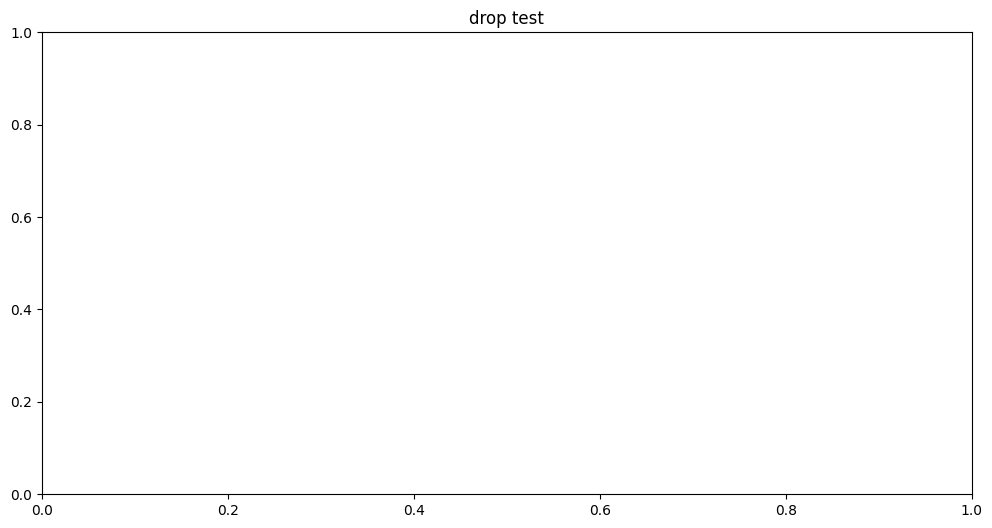

In [6]:
# ---- TEST DROP ----

def test_drop(shape_items, strip_width):
    items = extract_polys(shape_items)

    placed = []

    for i, item in enumerate(items[:3]):  # test first 3 only
        p = item["poly"]

        # place side by side
        if placed:
            right = max(x.bounds[2] for x in placed)
        else:
            right = 0

        moved = translate(p, right - p.bounds[0], 0)
        dropped = drop_piece(moved, [x for x in placed])

        placed.append(dropped)

    # render
    out = []
    for i,p in enumerate(placed):
        out.append({"poly":p,"part":"T","size":str(i)})

    render_layout(out, strip_width, "drop test")

def test_place_row(polys, strip_width=36):

    print("Testing place_row_and_score()")
    print("pieces:", len(polys))

    # take first 3 pieces only
    test_polys = polys[:3]

    placed = []  # nothing below yet

    layout, score = place_row_and_score(test_polys, placed, strip_width)

    print("best score:", score)

    if layout is None:
        print("❌ no layout returned")
        return

    render_layout(layout, strip_width, title="place_row test")



def test_build_row(shape_items, strip_width):

    print("\n==============================")
    print("TESTING ROW BUILDER")
    print("==============================")

    # convert to correct format
    remaining = []
    for s in shape_items:
        remaining.append({
            "poly": s["polygon"],   # shapely polygon
            "part": s["part"],
            "size": s["size"]
        })

    placed = []  # nothing placed yet

    row, used_idx = build_best_row(
        remaining,
        placed,
        strip_width,
        max_stack=5
    )

    if row is None:
        print("\n❌ No row returned")
        return

    print("\n✅ ROW BUILT")
    print("pieces in row:", len(row))

    for r in row:
        print(f'{r["part"]}-{r["size"]}',
              "top:", round(r["poly"].bounds[3],2))



        




design_folder = "JK-123"
STRIP_WIDTH = 36

shape_items = process_design_folder(design_folder)

test_drop(shape_items, STRIP_WIDTH)
polys = [s["polygon"] for s in shape_items]


#test_place_row(polys)


#test_build_row(shape_items, STRIP_WIDTH)
#row, used = build_best_row(polys, [], STRIP_WIDTH)


In [36]:

BEST_BRANCH_ROW_HEIGHTS = {}
CURRENT_BRANCH_ROW_HEIGHTS = {}

GLOBAL_BEST_HEIGHT = 1e18
GLOBAL_BEST_LAYOUT = None
VISITED_STATES = set()



design_folder = "JK-123"
STRIP_WIDTH = 36


shape_items = process_design_folder(design_folder)

run_global_search(shape_items, STRIP_WIDTH)



 GLOBAL SEARCH START

--- DEPTH 1 ---
Remaining pieces: 12
Possible stacks: 12

Stack:
   width used: 35.4
   - BACK XL | 12.1
   - FRONT XL | 12.1
   - BACK L | 11.2
   → height after row: 16.4
   → empty ratio: 0.1337

   --- DEPTH 2 ---
   Remaining pieces: 9
   Possible stacks: 9

   Stack:
      width used: 32.2
      - FRONT L | 11.2
      - BACK M | 10.5
      - FRONT M | 10.5
      → height after row: 30.9
      → empty ratio: 0.1617

      --- DEPTH 3 ---
      Remaining pieces: 6
      Possible stacks: 6

      Stack:
         width used: 34.55
         - SLEEVE-RIGHT XL | 9.52
         - SLEEVE-LEFT L | 8.7
         - SLEEVE-RIGHT L | 8.7
         - SLEEVE-LEFT M | 7.64
         → height after row: 38.748
         → empty ratio: 0.169

         --- DEPTH 4 ---
         Remaining pieces: 2
         Possible stacks: 2

         Stack:
            width used: 17.16
            - SLEEVE-LEFT XL | 9.52
            - SLEEVE-RIGHT M | 7.64
            → height after row: 45.248
  

KeyboardInterrupt: 

In [ ]:
shape_items